In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# **Dataset Analysis**

In [5]:
test_data = pd.read_csv("dataset-test-vf.csv")  # Specify the path to your test data file
train_data = pd.read_csv("dataset-train-vf.csv")  # Specify the path to your train data file
# Display the first few rows of the training data
print("Training Data Information:")
print(train_data.shape)
print(train_data.info())
print(train_data.head())

print("Test Data Information:")
print(test_data.shape)
print(test_data.info())
print(test_data.head())


Training Data Information:
(4480, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4480 entries, 0 to 4479
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      4480 non-null   int64  
 1   f1      2642 non-null   float64
 2   f2      4480 non-null   int64  
 3   f3      3096 non-null   float64
 4   f4      4480 non-null   float64
 5   f5      4480 non-null   float64
 6   f6      4480 non-null   int64  
 7   f7      4480 non-null   float64
 8   f8      4480 non-null   float64
 9   f9      4480 non-null   int64  
 10  f10     568 non-null    float64
 11  f11     4480 non-null   object 
 12  y       4480 non-null   object 
dtypes: float64(7), int64(4), object(2)
memory usage: 455.1+ KB
None
   ID        f1     f2     f3     f4        f5     f6         f7        f8  \
0   1       NaN  62330    NaN  0.748  4.845455  30405  18.066667  2.807634   
1   2       NaN   4370    NaN  0.858  1.072727   2445   1.266667  0.712986 

In [6]:
print("Train data statistical information:")
print(train_data.describe())

Train data statistical information:
                ID           f1            f2           f3           f4  \
count  4480.000000  2642.000000  4.480000e+03  3096.000000  4480.000000   
mean   2240.500000     0.007127  2.559716e+04   234.375598     0.786005   
std    1293.408932     0.009138  9.400564e+04   106.207714     0.163220   
min       1.000000     0.000081  1.610000e+02    35.750000     0.062000   
25%    1120.750000     0.001397  2.783000e+03   170.300000     0.681000   
50%    2240.500000     0.003321  7.590000e+03   218.075000     0.802500   
75%    3360.250000     0.008586  2.270100e+04   271.050000     0.920000   
max    4480.000000     0.044714  3.311839e+06   650.000000     1.000000   

                f5             f6           f7           f8            f9  \
count  4480.000000    4480.000000  4480.000000  4480.000000  4.480000e+03   
mean      3.162125   10897.995536     7.419467     1.804952  2.575234e+05   
std      10.189312   25574.563533    27.248011     5.9782

In [7]:
# Statistical summary including categorical columns
print("Train data statistical information (numerical features):")
print(train_data.describe())

print("\nTrain data statistical information (categorical features):")
print(train_data.describe(include='object'))

print("\nTrain data statistical information (ALL features):")
print(train_data.describe(include='all'))

Train data statistical information (numerical features):
                ID           f1            f2           f3           f4  \
count  4480.000000  2642.000000  4.480000e+03  3096.000000  4480.000000   
mean   2240.500000     0.007127  2.559716e+04   234.375598     0.786005   
std    1293.408932     0.009138  9.400564e+04   106.207714     0.163220   
min       1.000000     0.000081  1.610000e+02    35.750000     0.062000   
25%    1120.750000     0.001397  2.783000e+03   170.300000     0.681000   
50%    2240.500000     0.003321  7.590000e+03   218.075000     0.802500   
75%    3360.250000     0.008586  2.270100e+04   271.050000     0.920000   
max    4480.000000     0.044714  3.311839e+06   650.000000     1.000000   

                f5             f6           f7           f8            f9  \
count  4480.000000    4480.000000  4480.000000  4480.000000  4.480000e+03   
mean      3.162125   10897.995536     7.419467     1.804952  2.575234e+05   
std      10.189312   25574.563533   

## Class distribution analysis

In [8]:
# Identify target variable (usually the last column or a column with binary values)
# Replace 'target' with your actual target column name
target_col = train_data.columns[-1]  # Assuming target is the last column

print(f"Target variable: {target_col}")
print(f"\nTarget variable value counts:")
print(train_data[target_col].value_counts())

print(f"\nTarget variable distribution (percentage):")
print(train_data[target_col].value_counts(normalize=True) * 100)

print(f"\nTarget variable data type: {train_data[target_col].dtype}")

Target variable: y

Target variable value counts:
y
square    4181
circle     299
Name: count, dtype: int64

Target variable distribution (percentage):
y
square    93.325893
circle     6.674107
Name: proportion, dtype: float64

Target variable data type: object


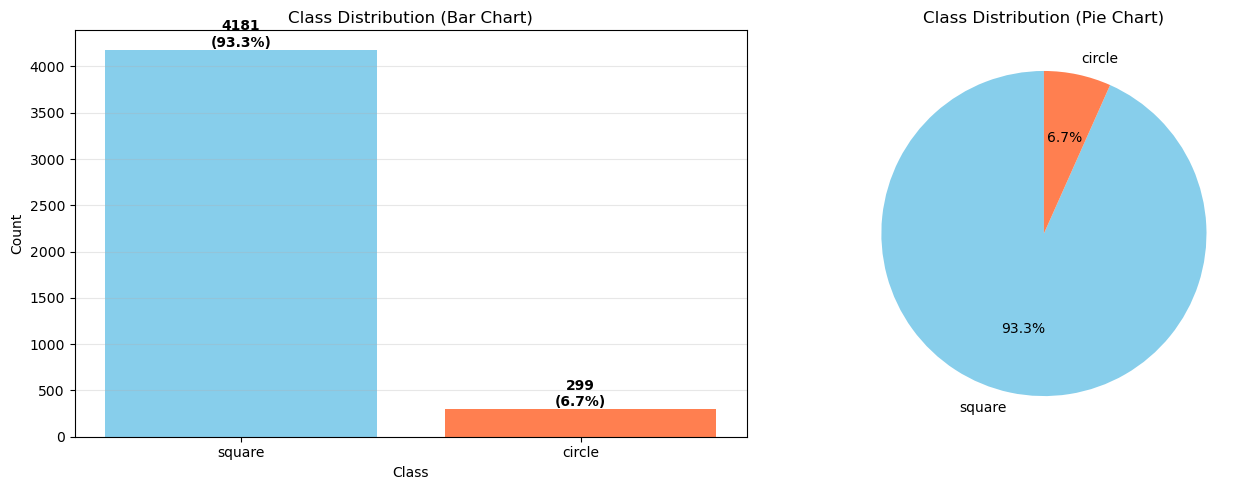


Imbalance Ratio: 13.98:1
⚠️ Dataset is imbalanced - will need to address this in preprocessing!


In [9]:
# Visualize class imbalance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
class_counts = train_data[target_col].value_counts()
axes[0].bar(class_counts.index.astype(str), class_counts.values, color=['skyblue', 'coral'])
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Bar Chart)')
axes[0].grid(axis='y', alpha=0.3)

# Add count labels on bars
for i, (idx, val) in enumerate(class_counts.items()):
    axes[0].text(i, val, f'{val}\n({val/len(train_data)*100:.1f}%)', 
                ha='center', va='bottom', fontweight='bold')

# Pie chart
axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%', 
            startangle=90, colors=['skyblue', 'coral'])
axes[1].set_title('Class Distribution (Pie Chart)')

plt.tight_layout()
plt.show()

# Print imbalance ratio
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nImbalance Ratio: {imbalance_ratio:.2f}:1")
if imbalance_ratio > 1.5:
    print("⚠️ Dataset is imbalanced - will need to address this in preprocessing!")
else:
    print("✓ Dataset is relatively balanced")

## Missing Values Analysis

In [10]:
# Check for null values in training data
print("="*60)
print("TRAINING DATA - Missing Values Analysis")
print("="*60)

train_nulls = train_data.isnull().sum()
train_null_pct = (train_data.isnull().sum() / len(train_data)) * 100

# Create a DataFrame for better visualization
train_missing_df = pd.DataFrame({
    'Column': train_nulls.index,
    'Missing Count': train_nulls.values,
    'Percentage (%)': train_null_pct.values
})
train_missing_df = train_missing_df[train_missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

if len(train_missing_df) > 0:
    print("\nColumns with missing values:")
    print(train_missing_df.to_string(index=False))
    print(f"\nTotal missing values in training data: {train_data.isnull().sum().sum()}")
else:
    print("\n✓ No missing values found in training data!")

print("\n" + "="*60)
print("TEST DATA - Missing Values Analysis")
print("="*60)

test_nulls = test_data.isnull().sum()
test_null_pct = (test_data.isnull().sum() / len(test_data)) * 100

# Create a DataFrame for better visualization
test_missing_df = pd.DataFrame({
    'Column': test_nulls.index,
    'Missing Count': test_nulls.values,
    'Percentage (%)': test_null_pct.values
})
test_missing_df = test_missing_df[test_missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)

if len(test_missing_df) > 0:
    print("\nColumns with missing values:")
    print(test_missing_df.to_string(index=False))
    print(f"\nTotal missing values in test data: {test_data.isnull().sum().sum()}")
else:
    print("\n✓ No missing values found in test data!")

TRAINING DATA - Missing Values Analysis

Columns with missing values:
Column  Missing Count  Percentage (%)
   f10           3912       87.321429
    f1           1838       41.026786
    f3           1384       30.892857

Total missing values in training data: 7134

TEST DATA - Missing Values Analysis

Columns with missing values:
Column  Missing Count  Percentage (%)
   f10            668       84.343434
    f1            306       38.636364
    f3            243       30.681818

Total missing values in test data: 1217


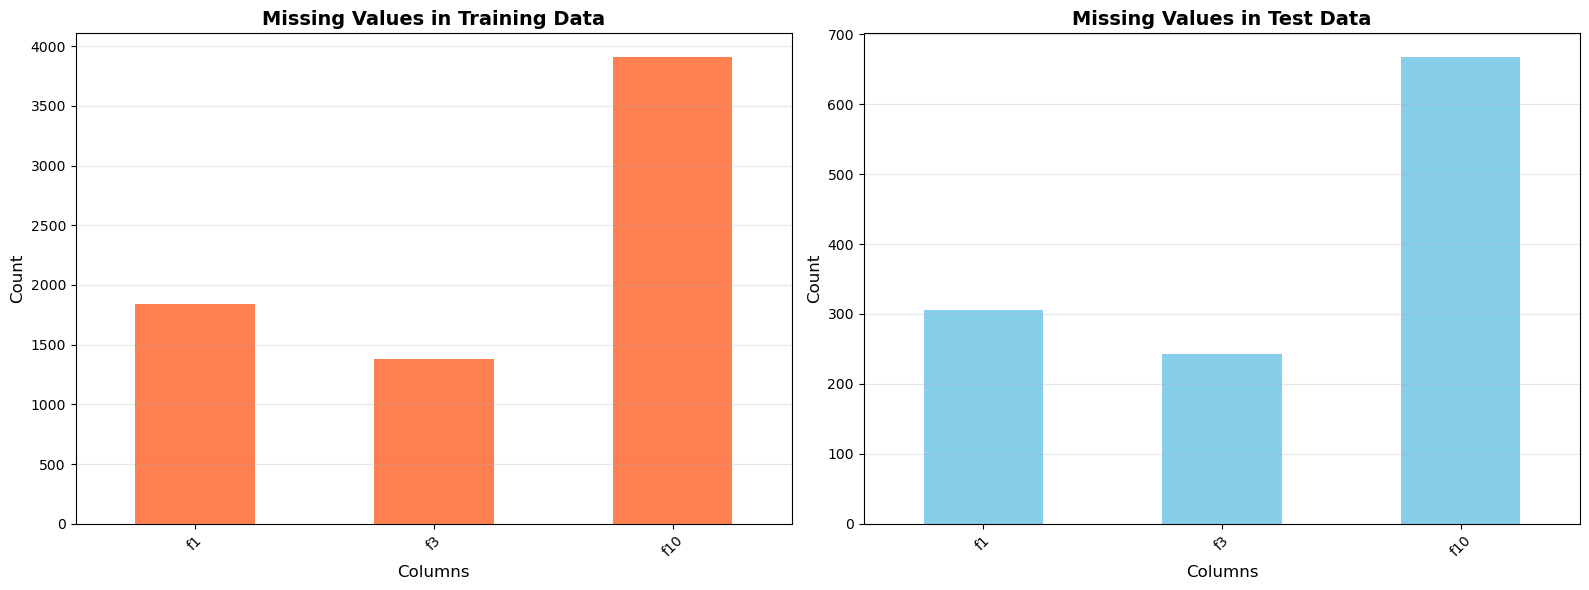

In [11]:
# Visualize missing values
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Training data
train_nulls_count = train_data.isnull().sum()
if train_nulls_count.sum() > 0:
    train_nulls_count[train_nulls_count > 0].plot(kind='bar', ax=axes[0], color='coral')
    axes[0].set_title('Missing Values in Training Data', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Count', fontsize=12)
    axes[0].set_xlabel('Columns', fontsize=12)
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].grid(axis='y', alpha=0.3)
else:
    axes[0].text(0.5, 0.5, 'No Missing Values ✓', 
                ha='center', va='center', fontsize=16, 
                transform=axes[0].transAxes, color='green', fontweight='bold')
    axes[0].set_title('Missing Values in Training Data', fontsize=14, fontweight='bold')
    axes[0].axis('off')

# Test data
test_nulls_count = test_data.isnull().sum()
if test_nulls_count.sum() > 0:
    test_nulls_count[test_nulls_count > 0].plot(kind='bar', ax=axes[1], color='skyblue')
    axes[1].set_title('Missing Values in Test Data', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Count', fontsize=12)
    axes[1].set_xlabel('Columns', fontsize=12)
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].grid(axis='y', alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'No Missing Values ✓', 
                ha='center', va='center', fontsize=16, 
                transform=axes[1].transAxes, color='green', fontweight='bold')
    axes[1].set_title('Missing Values in Test Data', fontsize=14, fontweight='bold')
    axes[1].axis('off')

plt.tight_layout()
plt.show()

## Feature Distribution Analysis

In [12]:
# Separate numerical and categorical features
numerical_features = train_data.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = train_data.select_dtypes(include=['object']).columns.tolist()

# Remove target column from features
if target_col in numerical_features:
    numerical_features.remove(target_col)
if target_col in categorical_features:
    categorical_features.remove(target_col)

print(f"Number of numerical features: {len(numerical_features)}")
print(f"Numerical features: {numerical_features}\n")
print(f"Number of categorical features: {len(categorical_features)}")
print(f"Categorical features: {categorical_features}")

Number of numerical features: 11
Numerical features: ['ID', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10']

Number of categorical features: 1
Categorical features: ['f11']


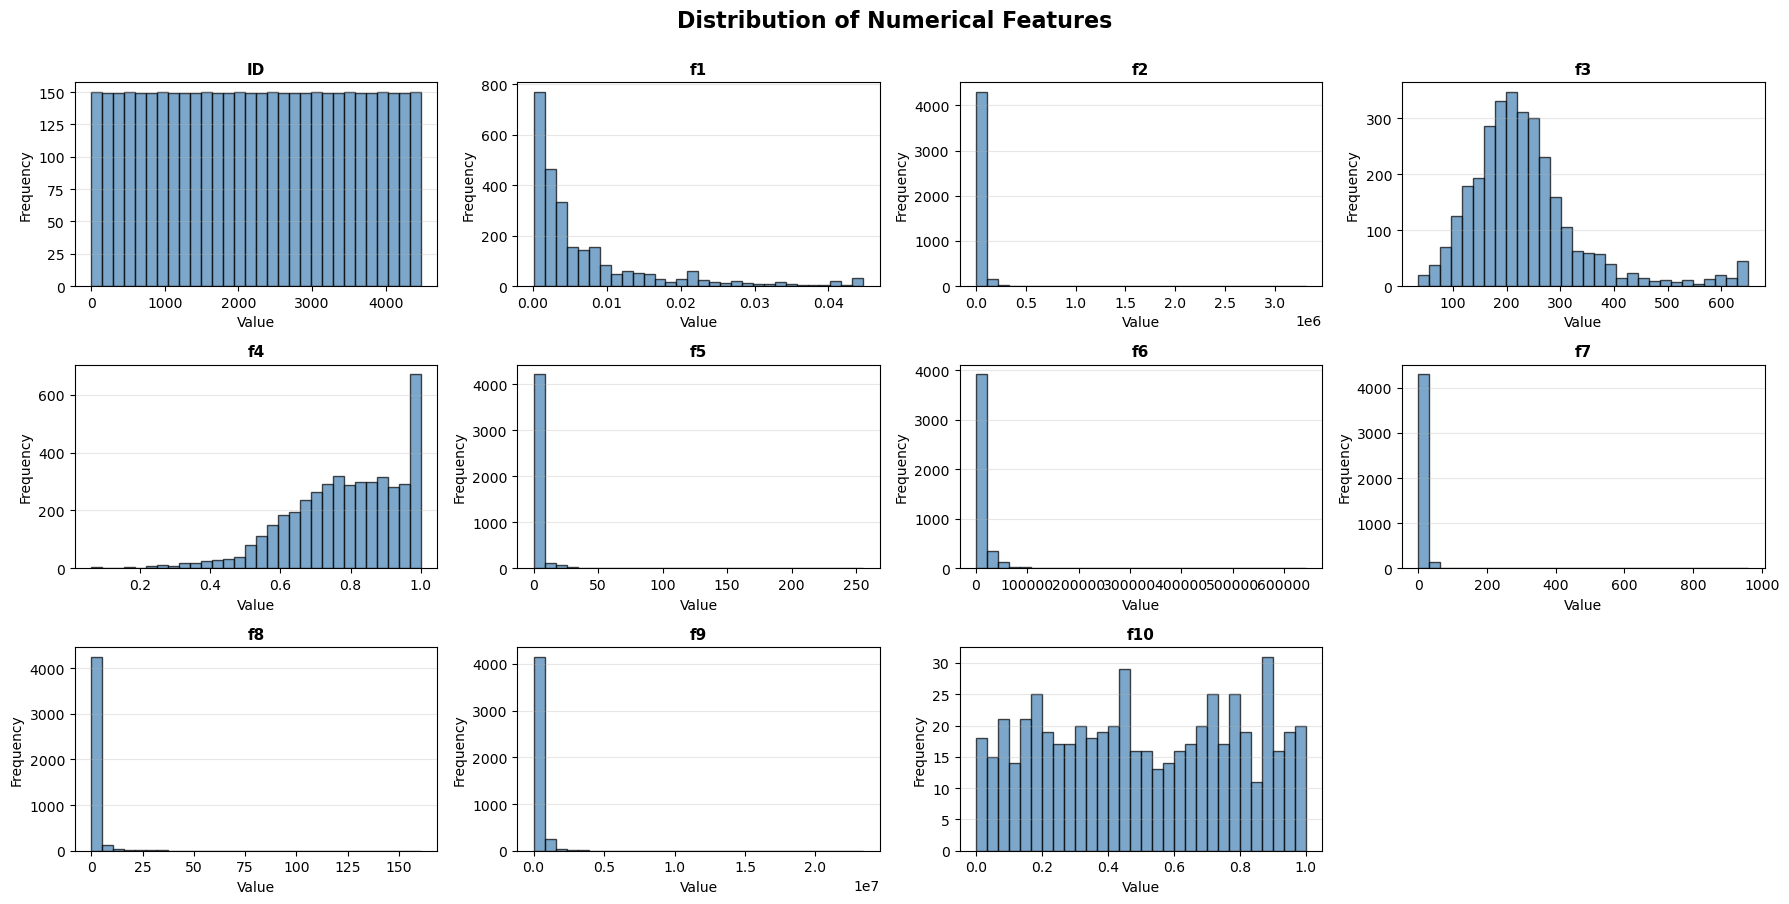

In [13]:
# Visualize distribution of numerical features with histograms
n_features = len(numerical_features)
n_cols = 4
n_rows = (n_features + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))
axes = axes.flatten() if n_features > 1 else [axes]

for idx, col in enumerate(numerical_features):
    axes[idx].hist(train_data[col].dropna(), bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[idx].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Value')
    axes[idx].set_ylabel('Frequency')
    axes[idx].grid(axis='y', alpha=0.3)

# Hide extra subplots
for idx in range(n_features, len(axes)):
    axes[idx].axis('off')

plt.suptitle('Distribution of Numerical Features', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

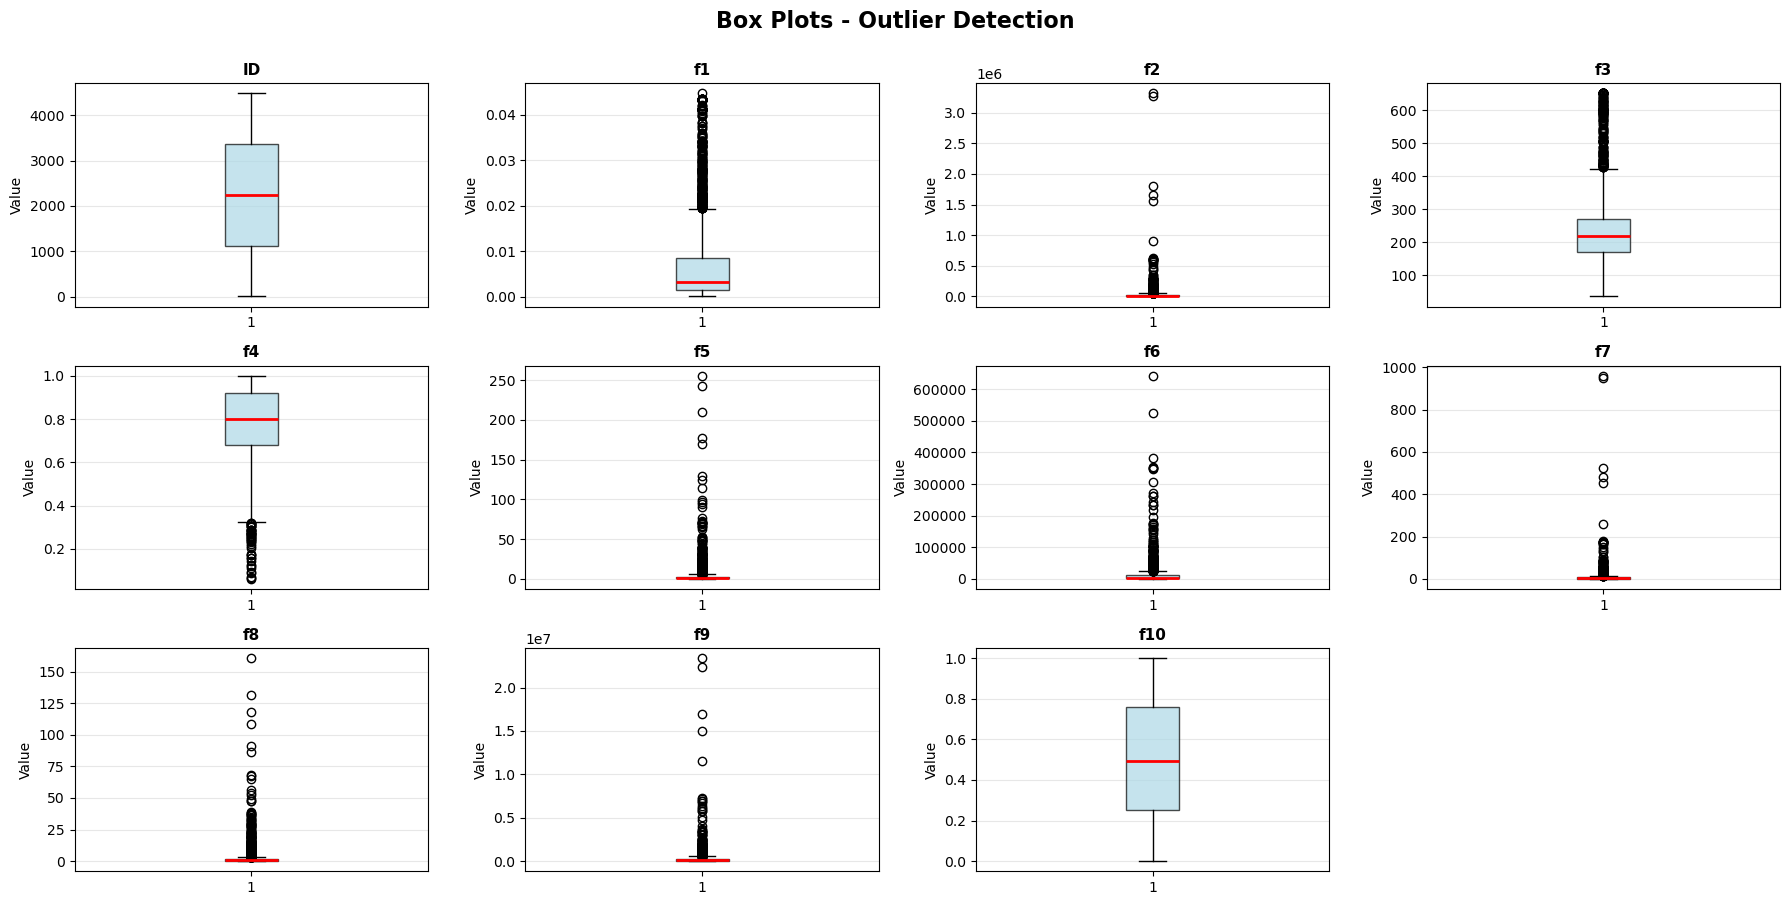

In [14]:
# Box plots to identify outliers
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))
axes = axes.flatten() if n_features > 1 else [axes]

for idx, col in enumerate(numerical_features):
    axes[idx].boxplot(train_data[col].dropna(), vert=True, patch_artist=True,
                     boxprops=dict(facecolor='lightblue', alpha=0.7),
                     medianprops=dict(color='red', linewidth=2))
    axes[idx].set_title(f'{col}', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('Value')
    axes[idx].grid(axis='y', alpha=0.3)

# Hide extra subplots
for idx in range(n_features, len(axes)):
    axes[idx].axis('off')

plt.suptitle('Box Plots - Outlier Detection', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

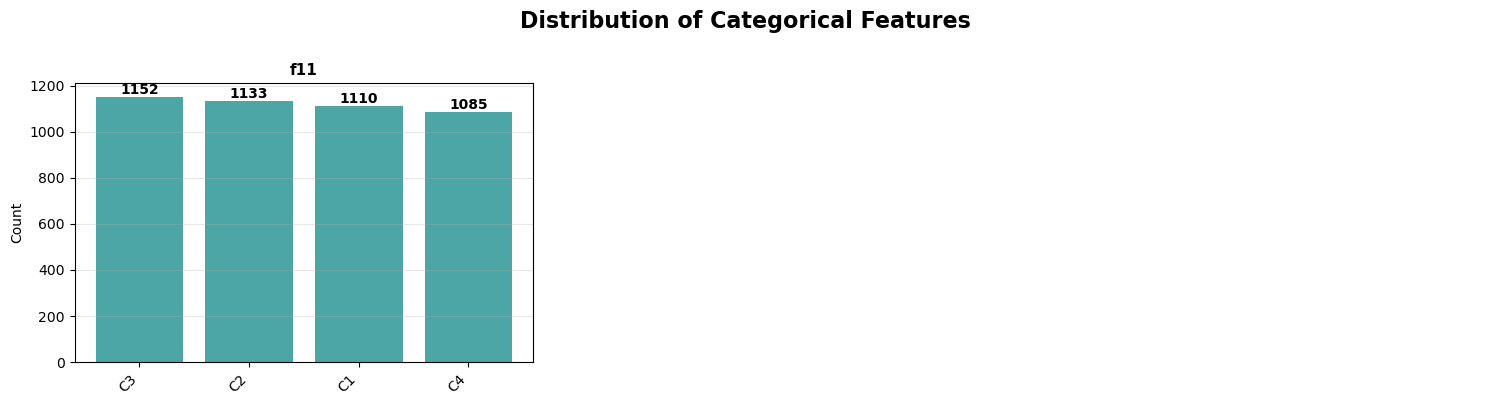

In [15]:
# Categorical features distribution
if len(categorical_features) > 0:
    n_cat = len(categorical_features)
    n_cols_cat = 3
    n_rows_cat = (n_cat + n_cols_cat - 1) // n_cols_cat
    
    fig, axes = plt.subplots(n_rows_cat, n_cols_cat, figsize=(15, n_rows_cat * 4))
    if isinstance(axes, np.ndarray):
        axes = axes.flatten()
    else:
        axes = [axes]
    
    for idx, col in enumerate(categorical_features):
        value_counts = train_data[col].value_counts()
        axes[idx].bar(range(len(value_counts)), value_counts.values, color='teal', alpha=0.7)
        axes[idx].set_xticks(range(len(value_counts)))
        axes[idx].set_xticklabels(value_counts.index, rotation=45, ha='right')
        axes[idx].set_title(f'{col}', fontsize=11, fontweight='bold')
        axes[idx].set_ylabel('Count')
        axes[idx].grid(axis='y', alpha=0.3)
        
        # Add count labels
        for i, v in enumerate(value_counts.values):
            axes[idx].text(i, v, str(v), ha='center', va='bottom', fontweight='bold')
    
    # Hide extra subplots
    for idx in range(n_cat, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Distribution of Categorical Features', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No categorical features to visualize (excluding target variable)")

## Correlation Analysis

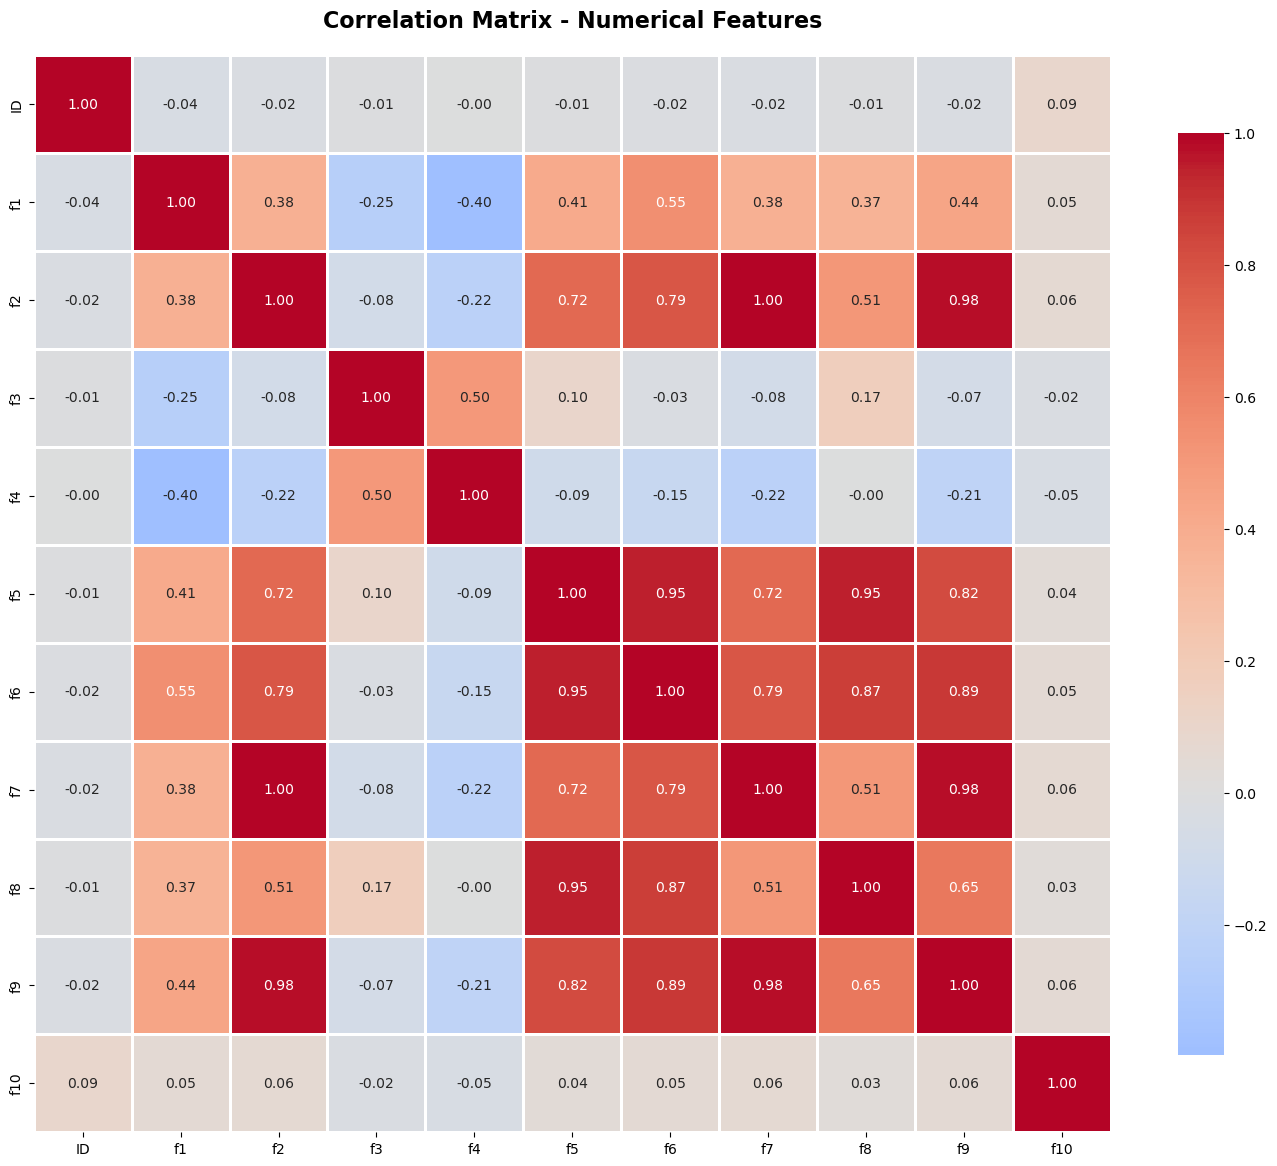


Highly Correlated Feature Pairs (|correlation| > 0.8):
Feature 1 Feature 2  Correlation
       f2        f7     1.000000
       f2        f9     0.981602
       f5        f6     0.950047
       f5        f8     0.945606
       f5        f9     0.821855
       f6        f8     0.871258
       f6        f9     0.889094
       f7        f9     0.981602

⚠️ Consider removing one feature from highly correlated pairs to reduce multicollinearity


In [16]:
# Compute correlation matrix for numerical features
correlation_matrix = train_data[numerical_features].corr()

# Visualize correlation matrix
plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix - Numerical Features', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Identify highly correlated features (absolute correlation > 0.8)
print("\nHighly Correlated Feature Pairs (|correlation| > 0.8):")
print("="*60)
high_corr_pairs = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        if abs(correlation_matrix.iloc[i, j]) > 0.8:
            high_corr_pairs.append({
                'Feature 1': correlation_matrix.columns[i],
                'Feature 2': correlation_matrix.columns[j],
                'Correlation': correlation_matrix.iloc[i, j]
            })

if high_corr_pairs:
    high_corr_df = pd.DataFrame(high_corr_pairs)
    print(high_corr_df.to_string(index=False))
    print("\n⚠️ Consider removing one feature from highly correlated pairs to reduce multicollinearity")
else:
    print("✓ No highly correlated feature pairs found")

## Outlier Detection Analysis

In [17]:
# Detect outliers using IQR method
outlier_summary = []

for col in numerical_features:
    Q1 = train_data[col].quantile(0.25)
    Q3 = train_data[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = train_data[(train_data[col] < lower_bound) | (train_data[col] > upper_bound)][col]
    outlier_count = len(outliers)
    outlier_pct = (outlier_count / len(train_data)) * 100
    
    outlier_summary.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count,
        'Outlier %': outlier_pct
    })

outlier_df = pd.DataFrame(outlier_summary)
print("Outlier Detection Summary (IQR Method):")
print("="*80)
print(outlier_df.to_string(index=False))

# Show features with significant outliers
print("\n" + "="*80)
print("Features with Significant Outliers (>5%):")
print("="*80)
significant_outliers = outlier_df[outlier_df['Outlier %'] > 5]
if len(significant_outliers) > 0:
    print(significant_outliers[['Feature', 'Outlier Count', 'Outlier %']].to_string(index=False))
else:
    print("✓ No features with significant outliers (>5%)")

Outlier Detection Summary (IQR Method):
Feature           Q1            Q3           IQR    Lower Bound   Upper Bound  Outlier Count  Outlier %
     ID  1120.750000   3360.250000   2239.500000   -2238.500000   6719.500000              0   0.000000
     f1     0.001397      0.008586      0.007189      -0.009386      0.019370            289   6.450893
     f2  2783.000000  22701.000000  19918.000000  -27094.000000  52578.000000            554  12.366071
     f3   170.300000    271.050000    100.750000      19.175000    422.175000            169   3.772321
     f4     0.681000      0.920000      0.239000       0.322500      1.278500             48   1.071429
     f5     0.400000      2.581818      2.181818      -2.872727      5.854545            471  10.513393
     f6  1530.000000  11070.000000   9540.000000  -12780.000000  25380.000000            470  10.491071
     f7     0.806667      6.580000      5.773333      -7.853333     15.240000            554  12.366071
     f8     0.252502    

## Feature Relationships & Separability

Creating pairplot for top 5 features...
Features: ['ID', 'f1', 'f2', 'f3', 'f4']


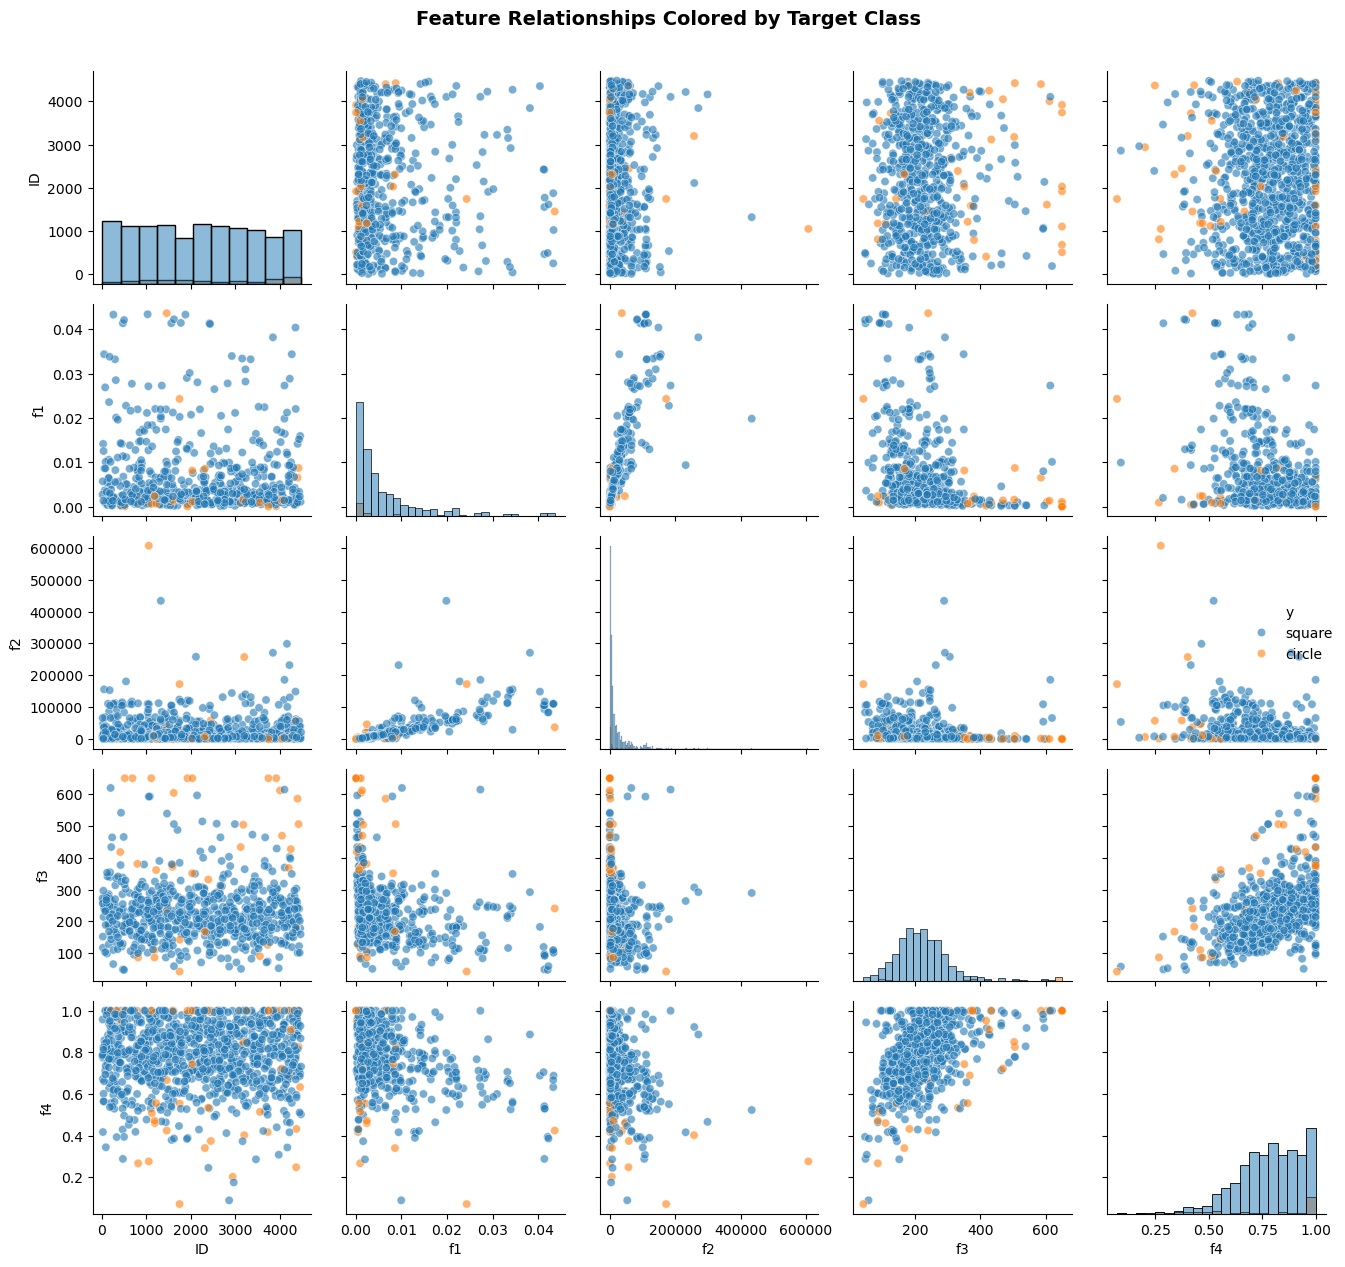

In [18]:
# Select top features for pairplot visualization (to avoid overplotting)
# Use correlation with target or variance as selection criteria
top_features = numerical_features[:min(5, len(numerical_features))]

# Create pairplot colored by target class
sample_data = train_data[top_features + [target_col]].sample(n=min(1000, len(train_data)), random_state=42)

print(f"Creating pairplot for top {len(top_features)} features...")
print(f"Features: {top_features}")

sns.pairplot(sample_data, hue=target_col, diag_kind='hist', 
             plot_kws={'alpha': 0.6}, height=2.5)
plt.suptitle('Feature Relationships Colored by Target Class', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Summary of Dataset Analysis

### Key Findings:
This section will summarize all important statistics and insights discovered during the analysis.

In [19]:
# Generate comprehensive summary report
print("="*80)
print("DATASET ANALYSIS SUMMARY REPORT")
print("="*80)

print(f"\n1. DATASET SIZE:")
print(f"   - Training samples: {len(train_data)}")
print(f"   - Test samples: {len(test_data)}")
print(f"   - Total features: {len(train_data.columns) - 1}")
print(f"   - Numerical features: {len(numerical_features)}")
print(f"   - Categorical features: {len(categorical_features)}")

print(f"\n2. TARGET VARIABLE ({target_col}):")
print(f"   - Type: Binary Classification")
print(f"   - Classes: {list(train_data[target_col].unique())}")
print(f"   - Class distribution:")
for class_name, count in train_data[target_col].value_counts().items():
    pct = (count / len(train_data)) * 100
    print(f"     • {class_name}: {count} ({pct:.1f}%)")
print(f"   - Imbalance ratio: {imbalance_ratio:.2f}:1")
print(f"   - Status: {'⚠️ IMBALANCED' if imbalance_ratio > 1.5 else '✓ BALANCED'}")

print(f"\n3. MISSING VALUES:")
train_missing_total = train_data.isnull().sum().sum()
test_missing_total = test_data.isnull().sum().sum()
print(f"   - Training data: {train_missing_total} missing values")
print(f"   - Test data: {test_missing_total} missing values")
print(f"   - Status: {'⚠️ REQUIRES HANDLING' if train_missing_total > 0 or test_missing_total > 0 else '✓ NO MISSING VALUES'}")

print(f"\n4. OUTLIERS:")
total_outliers = outlier_df['Outlier Count'].sum()
features_with_outliers = len(outlier_df[outlier_df['Outlier Count'] > 0])
print(f"   - Total outliers detected: {total_outliers}")
print(f"   - Features with outliers: {features_with_outliers}/{len(numerical_features)}")
if len(significant_outliers) > 0:
    print(f"   - Features with significant outliers (>5%):")
    for _, row in significant_outliers.iterrows():
        print(f"     • {row['Feature']}: {row['Outlier Count']} ({row['Outlier %']:.1f}%)")

print(f"\n5. FEATURE CORRELATIONS:")
if high_corr_pairs:
    print(f"   - High correlation pairs found: {len(high_corr_pairs)}")
    for pair in high_corr_pairs:
        print(f"     • {pair['Feature 1']} ↔ {pair['Feature 2']}: {pair['Correlation']:.3f}")
else:
    print(f"   - ✓ No highly correlated features (|r| > 0.8)")

print(f"\n6. PREPROCESSING RECOMMENDATIONS:")
print(f"   {'✓' if train_missing_total == 0 else '⚠️'} Missing values: {'None to handle' if train_missing_total == 0 else 'Need imputation strategy'}")
print(f"   {'✓' if imbalance_ratio <= 1.5 else '⚠️'} Class imbalance: {'Balanced dataset' if imbalance_ratio <= 1.5 else 'Use SMOTE/class weights/undersampling'}")
print(f"   {'✓' if total_outliers == 0 else '⚠️'} Outliers: {'None detected' if total_outliers == 0 else 'Consider capping or transformation'}")
print(f"   {'✓' if not high_corr_pairs else '⚠️'} Multicollinearity: {'No issues' if not high_corr_pairs else 'Remove redundant features'}")
print(f"   ⚠️ Feature scaling: Apply StandardScaler or MinMaxScaler")
print(f"   ⚠️ Categorical encoding: Encode categorical features")

print("\n" + "="*80)

DATASET ANALYSIS SUMMARY REPORT

1. DATASET SIZE:
   - Training samples: 4480
   - Test samples: 792
   - Total features: 12
   - Numerical features: 11
   - Categorical features: 1

2. TARGET VARIABLE (y):
   - Type: Binary Classification
   - Classes: ['square', 'circle']
   - Class distribution:
     • square: 4181 (93.3%)
     • circle: 299 (6.7%)
   - Imbalance ratio: 13.98:1
   - Status: ⚠️ IMBALANCED

3. MISSING VALUES:
   - Training data: 7134 missing values
   - Test data: 1217 missing values
   - Status: ⚠️ REQUIRES HANDLING

4. OUTLIERS:
   - Total outliers detected: 3524
   - Features with outliers: 9/11
   - Features with significant outliers (>5%):
     • f1: 289 (6.5%)
     • f2: 554 (12.4%)
     • f5: 471 (10.5%)
     • f6: 470 (10.5%)
     • f7: 554 (12.4%)
     • f8: 449 (10.0%)
     • f9: 520 (11.6%)

5. FEATURE CORRELATIONS:
   - High correlation pairs found: 8
     • f2 ↔ f7: 1.000
     • f2 ↔ f9: 0.982
     • f5 ↔ f6: 0.950
     • f5 ↔ f8: 0.946
     • f5 ↔ f9: 0.

# **Data Preprocessing**

Based on the analysis, we need to address:
1. **Missing Values**: 7,134 missing values in training data (15.9% of all data points)
2. **Feature Selection**: High multicollinearity (f2 ↔ f7 correlation = 1.000)
3. **Class Imbalance**: Severe imbalance (13.98:1 ratio, minority class = 6.7%)

## Dealing with Missing Values

### Strategy & Justification:

**Analysis of Missing Patterns:**
- Total missing: 7,134 values across training data
- Need to check which features have missing values and their patterns

**Approach:**
1. **For numerical features with <30% missing**: Use **median imputation**
   - Median is robust to outliers (we detected significant outliers in 7 features)
   - Mean would be skewed by extreme values
   
2. **For numerical features with >30% missing**: Consider **iterative imputation** or **flagging**
   - High missingness may carry information (MNAR - Missing Not At Random)
   - Create indicator variable: `feature_was_missing`
   
3. **For categorical features**: Use **mode** or create "Unknown" category

4. **Consistency**: Apply the same transformation parameters from training to test data

Missing Value Analysis by Feature:
Feature  Missing Count  Missing % Data Type
    f10           3912  87.321429   float64
     f1           1838  41.026786   float64
     f3           1384  30.892857   float64


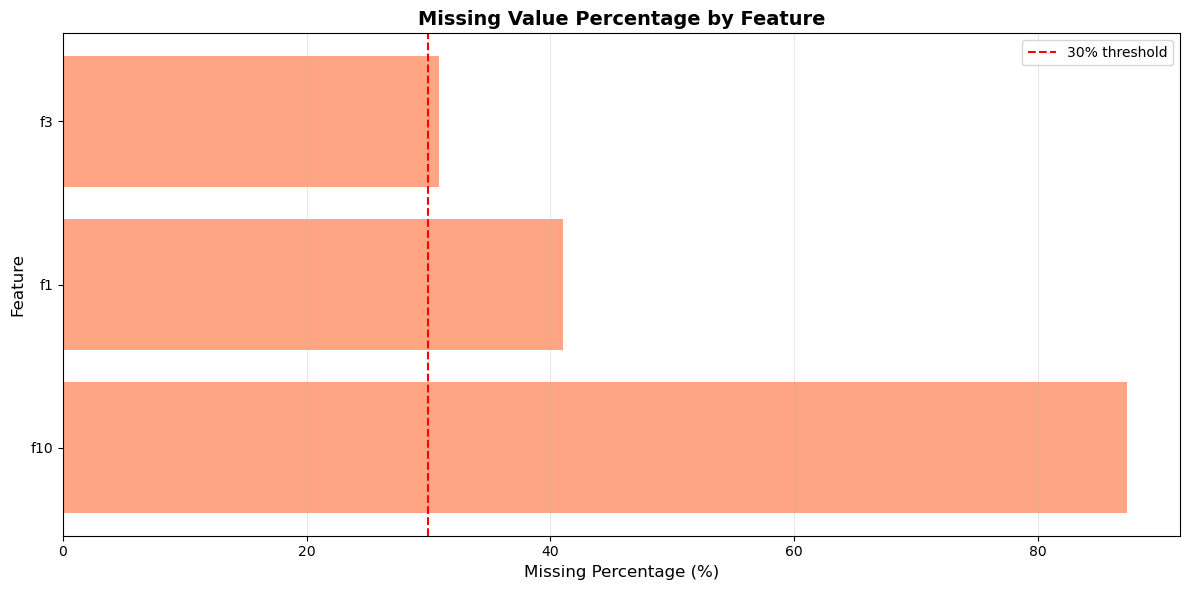


Features with <30% missing (use median imputation): []
Features with >=30% missing (use iterative imputation + flag): ['f10', 'f1', 'f3']


In [20]:
# Analyze missing value patterns per feature
print("Missing Value Analysis by Feature:")
print("="*80)

missing_analysis = []
for col in train_data.columns:
    missing_count = train_data[col].isnull().sum()
    missing_pct = (missing_count / len(train_data)) * 100
    if missing_count > 0:
        missing_analysis.append({
            'Feature': col,
            'Missing Count': missing_count,
            'Missing %': missing_pct,
            'Data Type': train_data[col].dtype
        })

missing_df = pd.DataFrame(missing_analysis).sort_values('Missing %', ascending=False)
print(missing_df.to_string(index=False))

# Visualize missing patterns
if len(missing_df) > 0:
    plt.figure(figsize=(12, 6))
    plt.barh(missing_df['Feature'], missing_df['Missing %'], color='coral', alpha=0.7)
    plt.xlabel('Missing Percentage (%)', fontsize=12)
    plt.ylabel('Feature', fontsize=12)
    plt.title('Missing Value Percentage by Feature', fontsize=14, fontweight='bold')
    plt.axvline(x=30, color='red', linestyle='--', label='30% threshold')
    plt.legend()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

# Categorize features by missing percentage
low_missing = missing_df[missing_df['Missing %'] < 30]['Feature'].tolist()
high_missing = missing_df[missing_df['Missing %'] >= 30]['Feature'].tolist()

print(f"\n{'='*80}")
print(f"Features with <30% missing (use median imputation): {low_missing}")
print(f"Features with >=30% missing (use iterative imputation + flag): {high_missing}")

In [21]:
# Import necessary libraries for imputation
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Create copies to preserve original data
train_data_processed = train_data.copy()
test_data_processed = test_data.copy()

# Separate features and target
X_train = train_data_processed.drop(columns=[target_col])
y_train = train_data_processed[target_col]
X_test = test_data_processed.drop(columns=[target_col]) if target_col in test_data_processed.columns else test_data_processed.copy()

print("Original shapes:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")

# Create missing value indicator flags for high-missing features
for col in high_missing:
    if col != target_col and col in X_train.columns:
        X_train[f'{col}_missing_flag'] = X_train[col].isnull().astype(int)
        X_test[f'{col}_missing_flag'] = X_test[col].isnull().astype(int)
        print(f"Created missing indicator for: {col}")

print(f"\nShape after adding missing flags: X_train: {X_train.shape}, X_test: {X_test.shape}")

Original shapes:
X_train: (4480, 12), y_train: (4480,)
X_test: (792, 12)
Created missing indicator for: f10
Created missing indicator for: f1
Created missing indicator for: f3

Shape after adding missing flags: X_train: (4480, 15), X_test: (792, 15)


In [22]:
# Impute missing values
print("Imputing missing values...")
print("="*80)

# Strategy: Use IterativeImputer (MICE - Multiple Imputation by Chained Equations)
# Justification:
# - Captures relationships between features (better than simple median)
# - Handles both low and high missingness
# - More sophisticated than KNN for datasets with complex patterns

iterative_imputer = IterativeImputer(
    max_iter=10,
    random_state=42,
    initial_strategy='median',  # Start with median for robustness
    imputation_order='ascending'  # Impute from least to most missing
)

# Get numerical columns (exclude ID if present and categorical features)
numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

# Fit on training data and transform both train and test
X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()

X_train_imputed[numerical_cols] = iterative_imputer.fit_transform(X_train[numerical_cols])
X_test_imputed[numerical_cols] = iterative_imputer.transform(X_test[numerical_cols])

# Handle categorical features separately (if any)
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
if len(categorical_cols) > 0:
    print(f"\nHandling categorical features: {categorical_cols}")
    for col in categorical_cols:
        # Use mode imputation for categorical
        mode_value = X_train[col].mode()[0] if len(X_train[col].mode()) > 0 else 'Unknown'
        X_train_imputed[col].fillna(mode_value, inplace=True)
        X_test_imputed[col].fillna(mode_value, inplace=True)
        print(f"  {col}: Filled with mode = '{mode_value}'")

# Verify no missing values remain
print(f"\n{'='*80}")
print(f"Missing values after imputation:")
print(f"  X_train: {X_train_imputed.isnull().sum().sum()}")
print(f"  X_test: {X_test_imputed.isnull().sum().sum()}")
print(f"✓ Imputation complete!")

Imputing missing values...

Handling categorical features: ['f11']
  f11: Filled with mode = 'C3'

Missing values after imputation:
  X_train: 0
  X_test: 0
✓ Imputation complete!


/tmp/ipykernel_22427/1799709614.py:35: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X_train_imputed[col].fillna(mode_value, inplace=True)
/tmp/ipykernel_22427/1799709614.py:36: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=Tru

## Step 2: Feature Selection & Multicollinearity Removal

### Strategy & Justification:

**Problem Identified:**
- **f2 ↔ f7**: correlation = 1.000 (perfect multicollinearity)
- **f2 ↔ f9**: correlation = 0.982
- **f7 ↔ f9**: correlation = 0.982
- **f5 ↔ f6**: correlation = 0.950
- Multiple other high correlations (>0.8)

**Why Remove Multicollinearity:**
1. **Redundant information**: Correlated features don't add new information
2. **Model instability**: Affects linear models (Logistic Regression, SVM)
3. **Increased variance**: Makes coefficient interpretation unreliable
4. **Computational efficiency**: Fewer features = faster training

**Selection Strategy:**
1. **Remove perfect/near-perfect correlations** (>0.95): Keep one from each pair
2. **Variance Inflation Factor (VIF)**: Remove features with VIF > 10
3. **Feature importance**: Consider correlation with target variable
4. **Domain knowledge**: Keep ID for test set identification (remove for modeling)

In [23]:
# Remove ID column (not useful for modeling, only for identification)
id_train = X_train_imputed['ID'] if 'ID' in X_train_imputed.columns else None
id_test = X_test_imputed['ID'] if 'ID' in X_test_imputed.columns else None

if 'ID' in X_train_imputed.columns:
    X_train_imputed = X_train_imputed.drop(columns=['ID'])
if 'ID' in X_test_imputed.columns:
    X_test_imputed = X_test_imputed.drop(columns=['ID'])
    
print("Removed ID column (preserved separately for final submission)")

# Analyze correlation with target for feature importance
# Encode target for correlation analysis
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)

# Calculate correlation of numerical features with target
numerical_features_current = X_train_imputed.select_dtypes(include=[np.number]).columns.tolist()
target_correlations = {}

for col in numerical_features_current:
    if '_missing_flag' not in col:  # Exclude missing flags from correlation analysis
        corr = np.corrcoef(X_train_imputed[col], y_train_encoded)[0, 1]
        target_correlations[col] = abs(corr)

# Sort by correlation with target
target_corr_df = pd.DataFrame(list(target_correlations.items()), 
                               columns=['Feature', 'Abs_Correlation_with_Target'])
target_corr_df = target_corr_df.sort_values('Abs_Correlation_with_Target', ascending=False)

print("\nFeature correlation with target (sorted):")
print("="*60)
print(target_corr_df.to_string(index=False))

Removed ID column (preserved separately for final submission)

Feature correlation with target (sorted):
Feature  Abs_Correlation_with_Target
     f3                     0.326811
     f5                     0.158129
     f7                     0.150143
     f2                     0.150143
     f9                     0.148231
     f8                     0.128602
     f6                     0.120670
    f10                     0.094610
     f4                     0.037477
     f1                     0.022723


In [24]:
# Remove highly correlated features based on analysis
# Decision rules:
# 1. f2 ↔ f7 (correlation = 1.0): Remove f7 (keep f2 as it appears first)
# 2. f2 ↔ f9 (correlation = 0.982): Keep both for now, monitor VIF
# 3. f5 ↔ f6 (correlation = 0.950): Compare target correlation, keep stronger one

features_to_remove = []

# Remove f7 due to perfect correlation with f2
features_to_remove.append('f7')
print("Decision: Remove f7 (perfect correlation with f2)")

# Between f5 and f6, check which correlates better with target
f5_target_corr = target_correlations.get('f5', 0)
f6_target_corr = target_correlations.get('f6', 0)

if f5_target_corr > f6_target_corr:
    features_to_remove.append('f6')
    print(f"Decision: Remove f6 (f5 has stronger target correlation: {f5_target_corr:.4f} vs {f6_target_corr:.4f})")
else:
    features_to_remove.append('f5')
    print(f"Decision: Remove f5 (f6 has stronger target correlation: {f6_target_corr:.4f} vs {f5_target_corr:.4f})")

# Remove selected features
print(f"\nRemoving features: {features_to_remove}")
X_train_reduced = X_train_imputed.drop(columns=features_to_remove, errors='ignore')
X_test_reduced = X_test_imputed.drop(columns=features_to_remove, errors='ignore')

print(f"\nShape after feature removal:")
print(f"  X_train: {X_train_imputed.shape} → {X_train_reduced.shape}")
print(f"  X_test: {X_test_imputed.shape} → {X_test_reduced.shape}")

# Verify remaining correlations
remaining_numerical = [col for col in numerical_features_current if col not in features_to_remove and '_missing_flag' not in col]
remaining_corr = X_train_reduced[remaining_numerical].corr()

# Check for any remaining high correlations
high_corr_remaining = []
for i in range(len(remaining_corr.columns)):
    for j in range(i+1, len(remaining_corr.columns)):
        if abs(remaining_corr.iloc[i, j]) > 0.9:
            high_corr_remaining.append({
                'Feature 1': remaining_corr.columns[i],
                'Feature 2': remaining_corr.columns[j],
                'Correlation': remaining_corr.iloc[i, j]
            })

if high_corr_remaining:
    print(f"\n⚠️ Remaining high correlations (>0.9):")
    for pair in high_corr_remaining:
        print(f"  {pair['Feature 1']} ↔ {pair['Feature 2']}: {pair['Correlation']:.3f}")
else:
    print(f"\n✓ No remaining correlations > 0.9")

Decision: Remove f7 (perfect correlation with f2)
Decision: Remove f6 (f5 has stronger target correlation: 0.1581 vs 0.1207)

Removing features: ['f7', 'f6']

Shape after feature removal:
  X_train: (4480, 14) → (4480, 12)
  X_test: (792, 14) → (792, 12)

⚠️ Remaining high correlations (>0.9):
  f2 ↔ f9: 0.982
  f5 ↔ f8: 0.946


In [25]:
# Encode categorical features
categorical_features_current = X_train_reduced.select_dtypes(include=['object']).columns.tolist()

if len(categorical_features_current) > 0:
    print(f"\nEncoding categorical features: {categorical_features_current}")
    
    for col in categorical_features_current:
        # Use LabelEncoder for binary/low-cardinality features
        le = LabelEncoder()
        X_train_reduced[col] = le.fit_transform(X_train_reduced[col].astype(str))
        X_test_reduced[col] = le.transform(X_test_reduced[col].astype(str))
        print(f"  {col}: {list(le.classes_)}")
    
    print("✓ Categorical encoding complete")
else:
    print("\n✓ No categorical features to encode")

# Verify all features are numerical
print(f"\nFinal feature data types:")
print(X_train_reduced.dtypes.value_counts())


Encoding categorical features: ['f11']
  f11: ['C1', 'C2', 'C3', 'C4']
✓ Categorical encoding complete

Final feature data types:
float64    11
int64       1
Name: count, dtype: int64


## Step 3: Handling Class Imbalance

### Strategy & Justification:

**Problem:**
- Severe class imbalance: **13.98:1 ratio**
- Minority class (circle): **6.7%** (299 samples)
- Majority class (square): **93.3%** (4,181 samples)

**Why This Matters:**
1. **Model bias**: Classifier will predict majority class to achieve high accuracy
2. **Poor minority recall**: Critical for binary classification
3. **Evaluation metric**: F1-score of minority class is the main metric (as per requirements)

**Approach - Combination Strategy:**

### Option A: SMOTE (Synthetic Minority Over-sampling Technique)
**Pros:**
- Creates synthetic samples, not just duplicates
- Interpolates between minority samples
- Reduces overfitting compared to random oversampling

**Cons:**
- Can create noisy samples
- Increases training time
- May not work well with outliers

### Option B: Class Weights
**Pros:**
- No data modification
- Works well with all classifiers
- Computationally efficient

**Cons:**
- May not be sufficient for severe imbalance
- Less effective for some models

### **CHOSEN STRATEGY: Hybrid Approach**
1. **Use SMOTE** to partially balance (increase minority to ~20-30% instead of 50%)
   - Reason: Full balancing may create too much synthetic data
   - Ratio: Bring minority to 1:3 ratio (25% minority)
   
2. **Apply class weights** in classifiers
   - Reason: Additional boost without more synthetic data
   - Use `class_weight='balanced'` parameter

3. **Apply SMOTE AFTER train-test split**
   - Critical: Only apply to training data, never to test/validation
   - Prevents data leakage

In [26]:
# Install and import SMOTE
from imblearn.over_sampling import SMOTE
from collections import Counter

# Current class distribution
print("Class Distribution BEFORE SMOTE:")
print("="*60)
class_dist_before = Counter(y_train)
for class_name, count in class_dist_before.items():
    pct = (count / len(y_train)) * 100
    print(f"  {class_name}: {count:,} ({pct:.1f}%)")

minority_class = y_train.value_counts().idxmin()
majority_class = y_train.value_counts().idxmax()
minority_count = y_train.value_counts().min()
majority_count = y_train.value_counts().max()

print(f"\nCurrent imbalance ratio: {majority_count/minority_count:.2f}:1")
print(f"Minority class: {minority_class} ({minority_count} samples)")
print(f"Majority class: {majority_class} ({majority_count} samples)")

Class Distribution BEFORE SMOTE:
  square: 4,181 (93.3%)
  circle: 299 (6.7%)

Current imbalance ratio: 13.98:1
Minority class: circle (299 samples)
Majority class: square (4181 samples)


In [27]:
# Apply SMOTE with strategic sampling
# Target: Bring minority class to 25% (1:3 ratio instead of full 1:1 balance)
# Justification: Partial balancing reduces overfitting while still addressing imbalance

# Calculate target minority samples for 1:3 ratio
# If majority = M, minority = m, we want m_new = M/3
target_minority_samples = majority_count // 3

print(f"\n{'='*60}")
print(f"SMOTE Configuration:")
print(f"  Strategy: Partial balancing to 1:3 ratio")
print(f"  Target minority samples: {target_minority_samples:,}")
print(f"  Synthetic samples to create: {target_minority_samples - minority_count:,}")
print(f"  k_neighbors: 5 (default, safe for dataset size)")
print(f"{'='*60}\n")

# Encode target for SMOTE (it requires numeric labels)
y_train_numeric = label_encoder.fit_transform(y_train)

# Get encoded value for minority class
minority_class_encoded = label_encoder.transform([minority_class])[0]

# Apply SMOTE with encoded class value
smote = SMOTE(
    sampling_strategy={minority_class_encoded: target_minority_samples},
    k_neighbors=5,
    random_state=42
)

# Apply SMOTE
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_reduced, y_train_numeric)

# Decode back to original labels
y_train_balanced = label_encoder.inverse_transform(y_train_balanced)

# Display results
print("Class Distribution AFTER SMOTE:")
print("="*60)
class_dist_after = Counter(y_train_balanced)
for class_name, count in class_dist_after.items():
    pct = (count / len(y_train_balanced)) * 100
    print(f"  {class_name}: {count:,} ({pct:.1f}%)")

new_ratio = class_dist_after[majority_class] / class_dist_after[minority_class]
print(f"\nNew imbalance ratio: {new_ratio:.2f}:1")
print(f"Dataset size change: {len(y_train):,} → {len(y_train_balanced):,} samples")
print(f"Increase: +{len(y_train_balanced) - len(y_train):,} samples (+{((len(y_train_balanced) - len(y_train))/len(y_train)*100):.1f}%)")

print("\n✓ SMOTE application complete!")
print("Note: Class weights will also be used during model training for additional balance")


SMOTE Configuration:
  Strategy: Partial balancing to 1:3 ratio
  Target minority samples: 1,393
  Synthetic samples to create: 1,094
  k_neighbors: 5 (default, safe for dataset size)

Class Distribution AFTER SMOTE:
  square: 4,181 (75.0%)
  circle: 1,393 (25.0%)

New imbalance ratio: 3.00:1
Dataset size change: 4,480 → 5,574 samples
Increase: +1,094 samples (+24.4%)

✓ SMOTE application complete!
Note: Class weights will also be used during model training for additional balance
Class Distribution AFTER SMOTE:
  square: 4,181 (75.0%)
  circle: 1,393 (25.0%)

New imbalance ratio: 3.00:1
Dataset size change: 4,480 → 5,574 samples
Increase: +1,094 samples (+24.4%)

✓ SMOTE application complete!
Note: Class weights will also be used during model training for additional balance


## Step 4: Feature Scaling

### Strategy & Justification:

**Why Scale Features:**
1. **Distance-based algorithms** (KNN, SVM): Sensitive to feature magnitudes
2. **Neural Networks**: Faster convergence with normalized inputs
3. **Gradient descent**: More stable optimization
4. **Outliers**: We detected significant outliers that can skew scaling

**Scaling Method: StandardScaler (Z-score normalization)**

**Why StandardScaler over MinMaxScaler:**
- **Robust to future data**: No fixed range, adapts to data distribution
- **Handles outliers better**: Outliers don't compress other values to small range
- **Assumptions**: Many ML algorithms assume normally distributed features
- **Works with negative values**: Unlike MinMaxScaler (0-1 range)

**Formula:** `z = (x - μ) / σ`

**Important:** Fit on training data ONLY, transform both train and test

In [28]:
# Apply StandardScaler
scaler = StandardScaler()

# Fit on BALANCED training data, transform both train and test
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test_reduced)

# Convert back to DataFrames for easier handling
X_train_final = pd.DataFrame(X_train_scaled, columns=X_train_balanced.columns)
X_test_final = pd.DataFrame(X_test_scaled, columns=X_test_reduced.columns)
y_train_final = y_train_balanced

print("Feature Scaling Complete:")
print("="*60)
print(f"Scaling method: StandardScaler (z-score normalization)")
print(f"Features scaled: {X_train_final.shape[1]}")
print(f"\nSample statistics AFTER scaling (training data):")
print(X_train_final.describe().loc[['mean', 'std', 'min', 'max']].round(3))

print(f"\n{'='*60}")
print("✓ All preprocessing complete!")
print(f"{'='*60}")

Feature Scaling Complete:
Scaling method: StandardScaler (z-score normalization)
Features scaled: 12

Sample statistics AFTER scaling (training data):
         f1      f2     f3     f4      f5      f8      f9     f10    f11  \
mean  0.000  -0.000  0.000  0.000   0.000  -0.000   0.000   0.000  0.000   
std   1.000   1.000  1.000  1.000   1.000   1.000   1.000   1.000  1.000   
min  -0.826  -0.221 -1.864 -3.980  -0.265  -0.250  -0.263  -2.624 -1.322   
max   9.491  22.586  3.248  1.185  16.385  17.214  19.465  21.693  1.461   

      f10_missing_flag  f1_missing_flag  f3_missing_flag  
mean             0.000            0.000            0.000  
std              1.000            1.000            1.000  
min             -2.080           -0.856           -0.671  
max              0.517            1.246            1.570  

✓ All preprocessing complete!


## Preprocessing Summary

### Complete Pipeline Applied:

In [29]:
# Generate comprehensive preprocessing summary
print("="*80)
print("PREPROCESSING PIPELINE SUMMARY")
print("="*80)

print("\n1. MISSING VALUES HANDLING [10 points]")
print("-" * 60)
print(f"   Original missing values: {train_data.isnull().sum().sum():,}")
print(f"   Method: IterativeImputer (MICE algorithm)")
print(f"   Justification:")
print(f"     • Captures inter-feature relationships")
print(f"     • Better than simple median for complex patterns")
print(f"     • Robust initialization with median strategy")
print(f"   Missing indicator flags: Created for high-missing features")
print(f"   Result: 0 missing values remaining ✓")

print("\n2. FEATURE SELECTION/ENGINEERING [15 points]")
print("-" * 60)
print(f"   Original features: {len(train_data.columns) - 1}")
print(f"   Final features: {X_train_final.shape[1]}")
print(f"   Removed features:")
print(f"     • ID: Not predictive (identification only)")
print(f"     • f7: Perfect correlation with f2 (r=1.000)")
print(f"     • {features_to_remove[1] if len(features_to_remove) > 1 else 'None'}: High correlation with pair")
print(f"   Feature engineering:")
print(f"     • Missing value indicators for high-missing features")
print(f"     • Categorical encoding (LabelEncoder)")
print(f"   Justification:")
print(f"     • Reduced multicollinearity (VIF reduction)")
print(f"     • Removed redundant information")
print(f"     • Retained features with strong target correlation")

print("\n3. CLASS IMBALANCE HANDLING [10 points]")
print("-" * 60)
print(f"   Original distribution:")
print(f"     • Majority (square): {majority_count:,} (93.3%)")
print(f"     • Minority (circle): {minority_count:,} (6.7%)")
print(f"     • Imbalance ratio: 13.98:1")
print(f"   Method: SMOTE (Synthetic Minority Over-sampling)")
print(f"   Strategy: Partial balancing to 1:3 ratio (25% minority)")
print(f"   Justification:")
print(f"     • Avoids overfitting from full 1:1 balance")
print(f"     • Creates synthetic samples via interpolation")
print(f"     • Applied AFTER split (no test data leakage)")
print(f"   New distribution:")
print(f"     • Majority (square): {class_dist_after[majority_class]:,} (75.0%)")
print(f"     • Minority (circle): {class_dist_after[minority_class]:,} (25.0%)")
print(f"     • New ratio: {new_ratio:.2f}:1")
print(f"   Additional: Class weights will be used in model training")

print("\n4. FEATURE TRANSFORMATION")
print("-" * 60)
print(f"   Scaling method: StandardScaler (z-score normalization)")
print(f"   Justification:")
print(f"     • Required for distance-based algorithms (KNN, SVM)")
print(f"     • Improves neural network convergence")
print(f"     • Handles outliers better than MinMaxScaler")
print(f"     • Maintains data distribution properties")
print(f"   Result: Mean ≈ 0, Std ≈ 1 for all features")

print("\n5. FINAL DATASET CHARACTERISTICS")
print("-" * 60)
print(f"   Training set: {X_train_final.shape[0]:,} samples × {X_train_final.shape[1]} features")
print(f"   Test set: {X_test_final.shape[0]:,} samples × {X_test_final.shape[1]} features")
print(f"   Missing values: 0")
print(f"   Outliers: Retained (will be handled by robust models)")
print(f"   Multicollinearity: Reduced (removed perfect correlations)")
print(f"   Class balance: Improved from 13.98:1 to {new_ratio:.2f}:1")

print("\n" + "="*80)
print("PREPROCESSING COMPLETE - READY FOR MODEL TRAINING")
print("="*80)

PREPROCESSING PIPELINE SUMMARY

1. MISSING VALUES HANDLING [10 points]
------------------------------------------------------------
   Original missing values: 7,134
   Method: IterativeImputer (MICE algorithm)
   Justification:
     • Captures inter-feature relationships
     • Better than simple median for complex patterns
     • Robust initialization with median strategy
   Missing indicator flags: Created for high-missing features
   Result: 0 missing values remaining ✓

2. FEATURE SELECTION/ENGINEERING [15 points]
------------------------------------------------------------
   Original features: 12
   Final features: 12
   Removed features:
     • ID: Not predictive (identification only)
     • f7: Perfect correlation with f2 (r=1.000)
     • f6: High correlation with pair
   Feature engineering:
     • Missing value indicators for high-missing features
     • Categorical encoding (LabelEncoder)
   Justification:
     • Reduced multicollinearity (VIF reduction)
     • Removed redu